# Anexo A1. El logo repetido

**Opcional** · **Dificultad: media** · Complementa al notebook 2

Objetivo: ver por qué un logo repetido en todas las páginas ensucia los fragmentos y cómo lo quita
`pdf.clean_pages()` antes del chunking.

In [1]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   /home/kerman/reto_1_1-2627-Rag-Modal-Multimodal-OCR/data/documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada
Trazas:      jsonl /home/kerman/reto_1_1-2627-Rag-Modal-Multimodal-OCR/trazas/trazas.jsonl  (alumno: KermanL)


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from rag_lab import pdf

doc = pdf.parse()
md_pages = pdf.markdown_by_page(doc)

## El logo repetido

La cabecera lleva el mismo logo en todas las páginas. En el PDF es una sola imagen incrustada (mismo `xref`)
que aparece en cada página. Docling no siempre la aparta como cabecera: a veces la trocea en varias imágenes
dentro del contenido. Cada una deja un `<!-- image -->` en el Markdown y ensucia los fragmentos.

In [3]:
imgs_pdf = pd.DataFrame(pdf.pdf_images())
print("Imágenes incrustadas por xref (en cuántas páginas aparece cada una):")
print(imgs_pdf.groupby(["xref", "ancho_px", "alto_px"])["pagina"].nunique().rename("páginas"))

Imágenes incrustadas por xref (en cuántas páginas aparece cada una):
xref  ancho_px  alto_px
11    849       131        20
18    800       600         1
Name: páginas, dtype: int64


In [4]:
imgs_docling = pd.DataFrame(pdf.docling_images(doc)).drop(columns=["item"])
print("Imágenes que Docling ha dejado en el contenido:", len(imgs_docling))
imgs_docling.groupby("pagina").size().rename("imágenes").to_frame().T

Imágenes que Docling ha dejado en el contenido: 37


pagina,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
imágenes,3,1,1,1,2,1,1,2,2,2,2,2,3,2,2,2,2,2,2,2


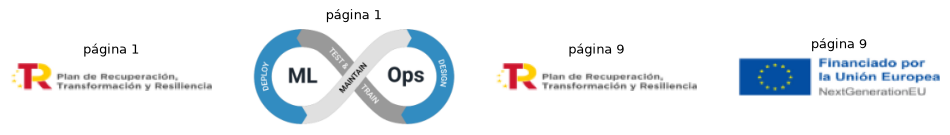

In [5]:
# Algunos recortes del logo que Docling ha puesto en el cuerpo
items = [f["item"] for f in pdf.docling_images(doc)]
fig, panels = plt.subplots(1, 4, figsize=(12, 1.6))
for panel, item in zip(panels, [items[0], items[2], items[12], items[13]]):
    panel.imshow(item.get_image(doc))
    panel.set_title(f"página {item.prov[0].page_no}", fontsize=9)
    panel.axis("off")
plt.show()

Deduplicación: buscamos las imágenes del PDF que se repiten en al menos la mitad de las páginas y quitamos del
documento de Docling las imágenes que caen dentro de su rectángulo. El diagrama y el cronograma se quedan.
Medimos el efecto sobre los fragmentos.

In [6]:
from rag_lab import chunking

clean_doc, removed = pdf.deduplicate(doc)
print("Imágenes quitadas:", len(removed))
print("Imágenes que quedan:", [(f["pagina"], f["tamano_px"]) for f in pdf.docling_images(clean_doc)])

before = chunking.by_headers(md_pages)
after = chunking.by_headers(pdf.clean_markdown(pdf.markdown_by_page(clean_doc)))
pd.DataFrame({
    "fragmentos": [len(before), len(after)],
    "con marcador de imagen": [sum("<!-- image -->" in f["texto"] for f in fr) for fr in (before, after)],
    "marcadores en total": [sum(f["texto"].count("<!-- image -->") for f in fr) for fr in (before, after)],
}, index=["sin deduplicar", "deduplicado"])

Imágenes quitadas: 35
Imágenes que quedan: [(1, (253, 122)), (13, (508, 62))]


,fragmentos,con marcador de imagen,marcadores en total
sin deduplicar,72,21,37
deduplicado,69,2,2


## Qué hemos visto

- Un logo repetido ensucia muchos fragmentos con marcadores `<!-- image -->` que no aportan nada.
- Se detecta porque es la misma imagen incrustada (mismo `xref`) en casi todas las páginas.